# Human-in-the-Loop 실습: 연장 일수를 고쳐 다시 묻고 승인일 때만 기록하기

**이 노트북에서 할 일**

1. 대출 연장 신청 한 건을 묻는 그래프에 승인 지점, 다시 묻기, 값 고쳐 넣기를 함께 붙입니다.
2. 허용 답 목록에 없는 답으로 다시 물은 뒤, 지난 체크포인트에 연장 일수를 고쳐 넣고 새 가지에서 다시 묻습니다.
3. 사람의 마지막 답 하나만 바꿔 다시 실행하고, 연장 기록 파일로 두 실행을 견줍니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
사람의 답은 우리가 셀에 적어 넣는 값(`"change"`·`"approve"`·`"reject"`)입니다.
실제 서비스라면 화면에서 사람이 고른 값을 같은 자리에 넣습니다.
01절처럼 매번 같은 값을 내는 우리 노드로, 기록 파일과 체크포인트를 출력으로 가릅니다.

연장 기록은 실제 서비스가 아니라, 기록 파일에 대출 키를 한 줄 적는 것으로 대신합니다.
노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
연장 기록 파일은 이 임시 폴더에 생기고, 실습 폴더에는 파일을 남기지 않습니다.
체크포인트는 메모리에만 저장하고, 읽어 오는 자료 파일은 없습니다.

걸린 시간은 재지 않았습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
그래프는 langgraph 1.2.11, 체크포인터는 langgraph-checkpoint 4.2.0에 들어 있습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 챕터 끝 실습 절이고 30분 안에 끝나는 분량입니다.
강사와 함께 첫 셀부터 차례로 실행하고, 따로 내는 과제는 없습니다.
01~03절에서 쓴 이름과 Ch 2에서 배운 문법만 씁니다.
셀 하나만 다시 실행하면 같은 스레드에 체크포인트가 더해지고, 기록 파일의 줄도 늘 수 있습니다.
처음 값으로 다시 보려면 1절 임시 폴더 셀부터 차례로 다시 실행합니다.

실습 폴더 `labs/part6/ch24-human-in-the-loop`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 그림입니다. 맨 위에 파란 상자 노드 look_up_loan 남은 날 3을 냄과 초록 상자 03절 값 고쳐 넣기 update_state로 연장 일수 14를 7로가 나란히 있고, 두 상자에서 파란 상자 노드 plan_extension 남은 날 더하기 연장 일수로 화살표가 갑니다. 그 아래 파란 상자 노드 ask_extension에는 02절 interrupt 한 번, 허용 답 목록 검사, 01절 멈춤 표시 뒤, approve일 때만 기록이 적혀 있습니다. 오른쪽 위 초록 상자 사람의 답 Command resume으로 change approve에서도 이 상자로 화살표가 들어갑니다. 노드 ask_extension에서 회색 마름모 조건 함수 after_answer로 화살표가 가고, 마름모에서 나가는 점선 둘 가운데 하나는 오류 칸에 글 있음 이름표 ask_again으로 노드 ask_extension에 되돌아가고, 다른 하나는 오류 칸 빈 글 이름표 END로 회색 둥근 상자 가상 끝점 END에 닿는 그림](attachment:04-1-세-절-기능을-붙인-연장-신청-그래프.png)

위에서 아래로 읽습니다.
파란 상자는 우리가 적은 노드이고, 초록 상자는 우리가 넣는 값과 사람의 답입니다.
회색 마름모는 노드로 등록하지 않는 조건 함수 `after_answer`이고, 마름모에서 나가는 점선 둘이 조건부 엣지입니다.
상자 안의 절 번호는 그 기능을 배운 절입니다.
고쳐 넣은 연장 일수는 계산 노드부터 다시 실행하는 새 가지로 들어갑니다.
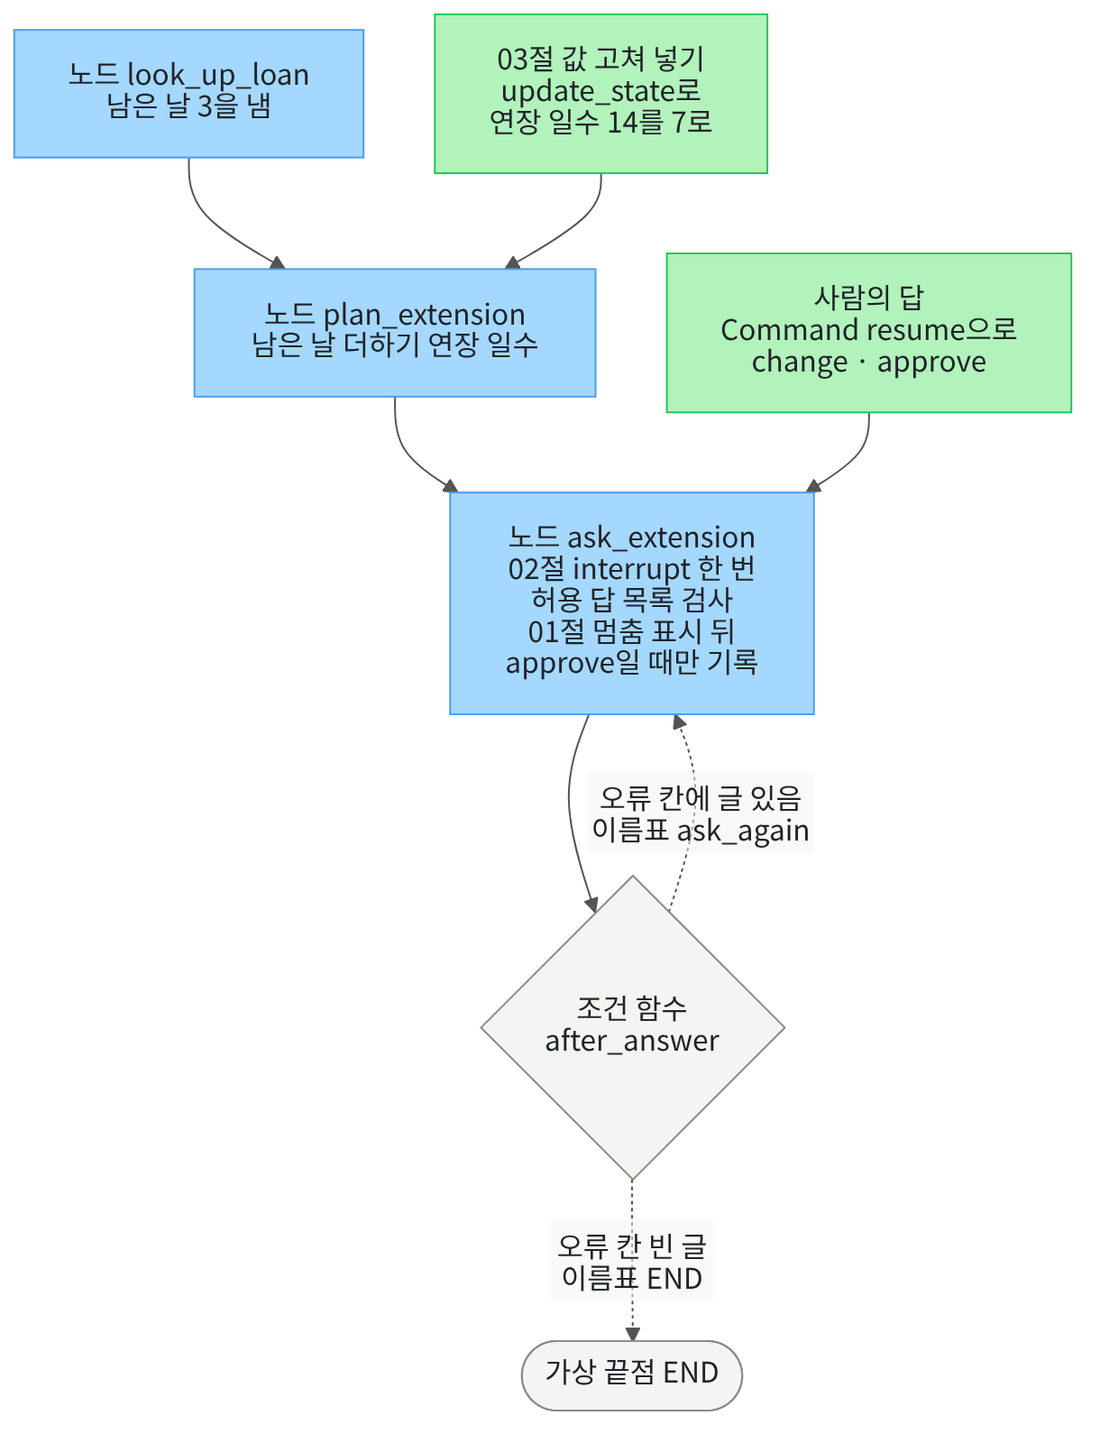

## 1. 준비

이번 절은 이 챕터의 실습입니다.
01절 승인 지점, 02절 다시 묻기, 03절 값 고쳐 넣기와 새 가지를 대출 연장 신청 한 건에 모읍니다.
첫 셀은 01절과 같은 패키지 둘을 설치하고, 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`과 `langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프 이름은 Ch 13 01절, 체크포인터 `InMemorySaver`는 Ch 23 01절과 같습니다.
함수 `interrupt`와 객체 `Command`는 01절에서 가져온 이름 그대로입니다.
마지막 가져오기 줄은 앞에서 배운 함수 넷을 도구 파일 `approval_tools.py`에서 가져옵니다.
이 절에서 새로 배우는 이름은 없습니다.

In [2]:
# 그래프 이름(Ch 13 01절)·체크포인터(Ch 23 01절)와, 01절에서 쓴 멈춤 표시 이름 둘을 가져옵니다
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
# interrupt는 노드를 멈추는 함수, Command는 멈춘 그래프에 사람의 답을 넘길 때 쓰는 객체입니다(01절)
from langgraph.types import Command, interrupt
# Ch 23 01·04·06절과 03절에서 배운 함수 넷을 도구 파일에서 가져옵니다
from approval_tools import append_key, find_before, print_history, read_record

print("langgraph.types에서 가져온 이름:", "Command, interrupt")
print("도구 파일에서 가져온 함수:", "append_key, find_before, print_history, read_record")

langgraph.types에서 가져온 이름: Command, interrupt
도구 파일에서 가져온 함수: append_key, find_before, print_history, read_record


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: append_key, find_before, print_history, read_record`가 보입니다.
함수 `append_key`와 `read_record`는 01절이 도구 파일로 옮겨 가져온 Ch 23 함수입니다.
함수 `print_history`는 Ch 23 01절, 함수 `find_before`는 이 챕터 03절 노트북 4절에서 처음 적은 함수입니다.
가져오기 줄 주석의 「03절」도 Ch 23이 아니라 이 챕터 03절입니다.
이 절에서 도구 파일에 더한 함수는 없습니다.

앞에서 배운 함수는 `approval_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있어, 작업 위치를 옮기기 전에 가져왔습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 01절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 절의 연장 기록 파일은 모두 이 임시 폴더에 생깁니다.
폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 이름의 앞머리만 확인합니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 23 01절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch24-04-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch24-04-이 들어 있는가:", "ch24-04-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch24-04-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch24-04-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 오늘 처리할 연장 신청

Ch 23 07절 실습에서는 이용자 `M-0317`의 대출 `loan-2307`을 기록했습니다.
이번에는 그 대출에 연장 신청이 들어왔습니다.
신청서에는 연장 일수가 14일로 적혀 있지만, 자료실 규칙은 한 번에 7일까지 연장합니다.
직원은 질문 값을 보고 연장을 승인하거나 거절하고, 승인일 때만 연장 기록을 적습니다.

다음 셀은 오늘 쓸 값 넷을 정하고 출처와 함께 출력합니다.
네 값 모두 실행 전에 정했습니다.

In [4]:
# 오늘 처리할 연장 신청의 값 넷을 정합니다(모두 실행 전에 정한 값)
member_id = "M-0317"
loan_key = "loan-2307"
print("이용자 번호:", member_id)
print("대출 키:", loan_key)
print("두 값의 출처: Ch 23 07절 실습의 이용자 번호와 대출 키 그대로")
# 신청서에 잘못 적힌 연장 일수와, 직원이 고쳐 넣을 연장 일수입니다
asked_days = 14
fixed_days = 7
print("신청서에 적힌 연장 일수:", asked_days, "| 고쳐 넣을 연장 일수:", fixed_days)
print("연장 일수 출처: 이 절에서 실행 전에 정한 값(자료실 규칙은 한 번에 7일까지로 정함)")

이용자 번호: M-0317
대출 키: loan-2307
두 값의 출처: Ch 23 07절 실습의 이용자 번호와 대출 키 그대로
신청서에 적힌 연장 일수: 14 | 고쳐 넣을 연장 일수: 7
연장 일수 출처: 이 절에서 실행 전에 정한 값(자료실 규칙은 한 번에 7일까지로 정함)


**결과 읽기** — 출력 줄 `이용자 번호: M-0317`과 `대출 키: loan-2307`로 오늘 쓸 값을 확인합니다.
출력 줄 `신청서에 적힌 연장 일수: 14 | 고쳐 넣을 연장 일수: 7`이 두 연장 일수입니다.
이용자 번호는 Ch 23 07절처럼 스레드 이름으로 씁니다.
연장 일수 14는 그래프에 처음 넣는 값이고, 7은 6절에서 지난 체크포인트에 고쳐 넣을 값입니다.

다음 셀은 받아들일 답 목록과, 사람이 차례로 넣을 답 둘을 정합니다.
허용 답 목록은 02절과 같은 두 값입니다.
첫 답 `change`는 연장 일수를 바꿔 달라는 뜻으로 적은 값이지만, 목록에 없습니다.

In [5]:
# 받아들일 답 목록과, 사람이 차례로 넣을 답 둘을 정합니다(실행 전에 정한 값)
allowed_answers = ["approve", "reject"]
# 첫 답 change는 연장 일수를 바꿔 달라는 뜻으로 적은 값이고, 허용 답 목록에는 없습니다
answer_turns = ["change", "approve"]
print("허용 답 목록:", allowed_answers)
print("사람의 답 차례:", answer_turns)
print("사람의 답 출처: 이 절에서 실행 전에 정한 값(실행 2에서는 마지막 답 하나만 바꿈)")

허용 답 목록: ['approve', 'reject']
사람의 답 차례: ['change', 'approve']
사람의 답 출처: 이 절에서 실행 전에 정한 값(실행 2에서는 마지막 답 하나만 바꿈)


**결과 읽기** — 출력 줄 `허용 답 목록: ['approve', 'reject']`와 `사람의 답 차례: ['change', 'approve']`입니다.
실행 1에서는 첫 질문에 `change`, 새 가지의 질문에 `approve`를 차례로 넣습니다.
실행 2에서는 마지막 답 하나만 `reject`로 바꿉니다.
사람의 답은 우리가 셀에 적어 넣는 값이고, 실제 서비스라면 화면에서 사람이 고른 값을 넣습니다.

## 3. 재료 · 상태 형식과 노드 셋, 조건 함수

다음 셀은 이 절의 상태 형식을 만듭니다.
칸 `loan_key`는 대출 키, 칸 `record_name`은 연장 기록 파일 이름, 칸 `days`는 연장 일수입니다.
칸 `left_days`는 지금 반납까지 남은 날, 칸 `due_days`는 연장 뒤 남은 날입니다.
칸 `answer`는 사람의 답이고, 칸 `error`에는 02절처럼 받아들이지 않은 까닭을 담습니다.
일곱 칸 모두 규칙을 적지 않아 새 값이 오면 덮어쓰고, 01~03절과 칸이 달라 이름도 새로 붙였습니다.

In [6]:
# 대출 키·기록 파일 이름·연장 일수·남은 날·연장 뒤 남은 날·사람의 답·오류 글 칸을 둔 상태 형식입니다(일곱 칸 모두 규칙 없음)
class ExtendState(TypedDict):
    loan_key: str
    record_name: str
    days: int
    left_days: int
    due_days: int
    answer: str
    error: str

**결과 읽기** — 정의 셀이라 출력이 없습니다.
이 절의 그래프는 이 상태 형식 하나를 씁니다.

다음 셀은 대출 조회 노드입니다.
지금 반납까지 남은 날을 칸 `left_days`에 냅니다.
남은 날 3일은 대출 기록을 읽는 대신 이 절에서 정해 둔 값입니다.
노드는 02·03절처럼 실행될 때마다 자기 이름을 목록 `extend_calls`에 적습니다.
이 목록은 6절 첫 셀에서 만듭니다.

In [7]:
# 대출 조회 노드: 지금 반납까지 남은 날을 칸 left_days에 냅니다
def look_up_loan(state):
    # 실행될 때마다 노드 이름을 목록에 적어, 몇 번 실행되었는지 셀 수 있게 합니다(02·03절 모양)
    extend_calls.append("look_up_loan")
    # 남은 날 3은 대출 기록을 읽는 대신 이 절에서 정해 둔 값입니다
    left_days = 3
    return {"left_days": left_days}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
노드는 자기 칸 `left_days`만 냅니다.

다음 셀은 계산 노드입니다.
남은 날에 연장 일수를 더해, 연장 뒤 남은 날을 칸 `due_days`에 냅니다.
연장 일수 14로 계산하면 17일, 7로 계산하면 10일이 됩니다.

In [8]:
# 계산 노드: 남은 날에 연장 일수를 더해, 연장 뒤 남은 날을 칸 due_days에 냅니다
def plan_extension(state):
    extend_calls.append("plan_extension")
    due_days = state["left_days"] + state["days"]
    return {"due_days": due_days}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
6절에서 연장 일수를 고쳐 넣으면, 새 가지에서는 이 노드부터 다시 실행됩니다.

다음 셀은 확인 노드입니다.
01절 `ask_then_charge`처럼 먼저 멈춤 표시로 묻고, 답이 `approve`일 때만 연장 기록을 적습니다.
02절 `ask_once`처럼 함수 `interrupt`는 한 번만 부르고, 목록에 없는 답이면 오류 글을 칸 `error`에 냅니다.
질문 값에는 연장 일수, 연장 뒤 남은 날, 오류 글을 담습니다.

In [9]:
# 확인 노드: 질문 값으로 멈추고, 허용 답 목록에 든 답만 받아 approve일 때만 연장 기록을 적습니다(01·02절 모양)
def ask_extension(state):
    extend_calls.append("ask_extension")
    question = {"days": state["days"], "due_days": state["due_days"], "error": state["error"]}
    # 처음 부를 때 이 줄에서 멈추고, 이어 갈 때는 사람의 답을 내놓습니다(interrupt는 한 번만 부름)
    answer = interrupt(question)
    if answer in allowed_answers:
        # 적는 줄은 멈춤 표시 뒤에 있어, 답이 approve일 때만 닿습니다
        if answer == "approve":
            append_key(state["record_name"], state["loan_key"])
        return {"answer": answer, "error": ""}
    return {"error": "허용하지 않는 값: " + answer}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
연장 기록을 적는 줄은 멈춤 표시 뒤, 목록 검사 안에 있습니다.
01절에서 본 것처럼 이어 갈 때 노드는 첫 줄부터 다시 실행됩니다.
그래도 적는 줄에는 사람의 답을 받은 뒤에만 닿습니다.

다음 셀은 02절의 조건 함수 `after_answer`를 그대로 다시 적습니다.
오류 칸이 빈 글이면 끝점 `END`를, 글이 있으면 이름표 `"ask_again"`을 내놓습니다.
노트북이 가져온 이름 `END`에 기대는 함수라, 도구 파일에 두지 않고 노트북에 적습니다.

In [10]:
# 칸 error를 보고, 오류 글이 없으면 끝점 END를, 있으면 이름표 "ask_again"을 내놓는 조건 함수입니다
def after_answer(state):
    if state["error"] == "":
        return END
    return "ask_again"

**결과 읽기** — 정의 셀이라 출력이 없습니다.
02절 노트북의 조건 함수 셀과 글자까지 같은 셀입니다.

## 4. 조립 · 노드를 등록하고 엣지로 잇기

다음 셀은 설계 객체를 만들고 노드 셋을 등록합니다.

In [11]:
# 설계 객체를 만들고, 노드 셋을 등록합니다
builder = StateGraph(ExtendState)
builder.add_node("look_up_loan", look_up_loan)
builder.add_node("plan_extension", plan_extension)
builder.add_node("ask_extension", ask_extension)
print("등록한 노드:", list(builder.nodes))

등록한 노드: ['look_up_loan', 'plan_extension', 'ask_extension']


**결과 읽기** — 출력 줄 `등록한 노드: ['look_up_loan', 'plan_extension', 'ask_extension']`입니다.

다음 셀은 노드 셋을 고정 엣지로 차례로 잇고, 확인 노드 뒤에는 02절처럼 조건부 엣지를 적습니다.
이름표 표는 이름표 `"ask_again"`을 같은 노드로, 끝점 `END`를 끝점으로 잇습니다.

In [12]:
# 노드 셋을 고정 엣지로 잇고, 확인 노드 뒤에는 02절처럼 조건부 엣지를 적습니다
builder.add_edge(START, "look_up_loan")
builder.add_edge("look_up_loan", "plan_extension")
builder.add_edge("plan_extension", "ask_extension")
# 이름표 ask_again은 같은 노드로 되돌아가 다시 묻고, 끝점 END는 그래프를 마칩니다
path_map = {"ask_again": "ask_extension", END: END}
builder.add_conditional_edges("ask_extension", after_answer, path_map)
print("고정 엣지로 적은 수:", len(builder.edges))
print("조건부 엣지를 적은 노드 수:", len(builder.branches))

고정 엣지로 적은 수: 3
조건부 엣지를 적은 노드 수: 1


**결과 읽기** — 출력 줄 `고정 엣지로 적은 수: 3`과 `조건부 엣지를 적은 노드 수: 1`입니다.
고정 엣지 셋은 `START` → `look_up_loan` → `plan_extension` → `ask_extension` 차례입니다.
확인 노드 다음에 갈 곳은 조건 함수가 고릅니다.
설계 객체 `builder`는 두 실행에 함께 씁니다.

## 5. 결과를 볼 기록 장치

결과는 앞에서 배운 함수와 목록으로 봅니다.
함수 `print_history`는 체크포인트 목록을 한 줄씩 출력하고, 함수 `find_before`는 돌아갈 체크포인트를 고릅니다.
함수 `read_record`는 연장 기록 파일의 줄을 목록으로 내놓습니다.
노드가 이름을 적는 목록 `extend_calls`로는 노드마다 실행된 횟수를 셉니다.

## 6. 실행 1 · 다시 묻고, 고쳐 넣은 값으로 새 가지에서 승인하기

다음 셀은 실행 1의 그래프를 컴파일합니다.
체크포인터를 붙여야 멈춘 자리와 지난 체크포인트가 남습니다.
노드가 이름을 적을 목록과 스레드 설정도 여기서 만듭니다.

In [13]:
# 실행 1의 그래프: 설계 객체에 체크포인터를 붙여 컴파일하고, 노드가 이름을 적을 목록을 만듭니다
one_graph = builder.compile(checkpointer=InMemorySaver())
extend_calls = []
# 스레드 이름은 이용자 번호입니다(Ch 23 07절처럼)
one_config = {"configurable": {"thread_id": member_id}}
print("스레드 이름:", one_config["configurable"]["thread_id"])
print("실행 기록 목록:", extend_calls)

스레드 이름: M-0317
실행 기록 목록: []


**결과 읽기** — 출력 줄 `스레드 이름: M-0317`과 `실행 기록 목록: []`입니다.

다음 셀은 연장 신청을 입력으로 넣어 첫 실행을 합니다.
연장 일수는 신청서에 적힌 14이고, 기록 파일 이름은 `extend-1.record`입니다.
03절처럼 셀을 실행하기 전 목록 길이를 적어 두고, 이 셀에서 새로 적힌 이름만 잘라 출력합니다.
실행 전에 예상해 봅니다.
노드 셋이 차례로 실행되고, 확인 노드의 멈춤 표시에서 멈출 것입니다.

In [14]:
# 연장 신청을 입력으로 넣어 첫 실행을 하고, 이 셀에서 실행된 노드와 질문 값을 봅니다
one_input = {"loan_key": loan_key, "record_name": "extend-1.record", "days": asked_days, "left_days": 0, "due_days": 0, "answer": "대기", "error": ""}
call_count = len(extend_calls)
one_result = one_graph.invoke(one_input, one_config)
print("이 셀에서 실행된 노드:", extend_calls[call_count:])
print("질문 값:", one_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['look_up_loan', 'plan_extension', 'ask_extension']
질문 값: {'days': 14, 'due_days': 17, 'error': ''}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['look_up_loan', 'plan_extension', 'ask_extension']`입니다.
출력 줄 `질문 값: {'days': 14, 'due_days': 17, 'error': ''}`로, 연장 뒤 남은 날 17을 물으며 멈췄습니다.
직원은 이 질문 값을 보고, 연장 일수가 규칙보다 길다는 것을 압니다.

다음 셀은 사람의 첫 답 `change`로 이어 갑니다.
실행 전에 예상해 봅니다.
답이 허용 답 목록에 없으니, 02절처럼 확인 노드가 오류 글을 담아 같은 자리에서 다시 물을 것입니다.
연장 일수는 답으로 바뀌지 않고, 기록도 적지 않을 것입니다.

In [15]:
# 사람의 첫 답 change로 이어 가고, 이 셀에서 실행된 노드와 다시 물은 질문 값을 봅니다
call_count = len(extend_calls)
one_result = one_graph.invoke(Command(resume=answer_turns[0]), one_config)
print("이 셀에서 실행된 노드:", extend_calls[call_count:])
print("다시 물은 질문 값:", one_result["__interrupt__"][0].value)

이 셀에서 실행된 노드: ['ask_extension', 'ask_extension']
다시 물은 질문 값: {'days': 14, 'due_days': 17, 'error': '허용하지 않는 값: change'}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['ask_extension', 'ask_extension']`입니다.
확인 노드가 첫 줄부터 다시 실행되어 답을 받고, 조건부 엣지로 되돌아가 한 번 더 실행되었습니다.
출력 줄 `다시 물은 질문 값: {'days': 14, 'due_days': 17, 'error': '허용하지 않는 값: change'}`로 까닭을 담아 멈췄습니다.
연장 일수는 14 그대로이고, 사람의 답으로는 이 값을 바꿀 수 없습니다.

다음 셀은 이 스레드의 체크포인트 목록을 받아, 함수 `print_history`로 한 줄씩 봅니다.
03절처럼 목록은 최신 것부터 놓입니다.

In [16]:
# 스레드의 체크포인트 목록을 받아 수를 세고, 한 줄씩 봅니다(목록은 최신 것부터)
one_history = list(one_graph.get_state_history(one_config))
print("체크포인트 수:", len(one_history))
print_history(one_history)

체크포인트 수: 5
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
3 | loop | ('ask_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 14, 'left_days': 3, 'due_days': 17, 'answer': '대기', 'error': '허용하지 않는 값: change'}
2 | loop | ('ask_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 14, 'left_days': 3, 'due_days': 17, 'answer': '대기', 'error': ''}
1 | loop | ('plan_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 14, 'left_days': 3, 'due_days': 0, 'answer': '대기', 'error': ''}
0 | loop | ('look_up_loan',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 14, 'left_days': 0, 'due_days': 0, 'answer': '대기', 'error': ''}
-1 | input | ('__start__',) | {}


**결과 읽기** — 출력 줄 `체크포인트 수: 5`입니다.
라벨 줄 아래 맨 위 줄은 단계 3이고, 칸 `error`에 오류 글이 든 다시 물은 자리입니다.
그 아래 단계 2 줄은 첫 질문에서 멈춘 자리이고, 칸 `due_days`가 `17`입니다.
단계 1 줄은 다음 노드가 `('plan_extension',)`이고, 칸 `left_days`가 이미 `3`입니다.

단계 1 줄은 대출 조회를 마치고 계산 노드를 실행하기 전의 자리입니다.
이 자리로 돌아가면, 남은 날은 그대로 두고 연장 일수만 고쳐 다시 계산할 수 있습니다.

In [17]:
# 목록에서 다음 노드가 plan_extension인 체크포인트를 고르고, 그 한 줄을 봅니다
chosen = find_before(one_history, "plan_extension")
print_history([chosen])
# 목록 맨 앞(다시 물은 자리)의 설정을 따로 담아 둡니다(설정에 든 아이디는 실행마다 달라 출력하지 않음)
paused_config = one_history[0].config
print("따로 담아 둔 체크포인트의 연장 일수:", one_history[0].values["days"])

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
1 | loop | ('plan_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 14, 'left_days': 3, 'due_days': 0, 'answer': '대기', 'error': ''}
따로 담아 둔 체크포인트의 연장 일수: 14


**결과 읽기** — 라벨 줄 아래 한 줄은 `1 | loop | ('plan_extension',)`로 시작합니다.
위 목록의 단계 1 줄과 같은 체크포인트입니다.
출력 줄 `따로 담아 둔 체크포인트의 연장 일수: 14`로, 다시 물은 자리의 설정을 담아 두었습니다.
설정 딕셔너리에는 실행마다 바뀌는 체크포인트 아이디가 들어 있어 출력하지 않았습니다.

다음 셀은 고른 체크포인트에 연장 일수 7을 고쳐 넣습니다.
그다음 새 체크포인트의 설정으로, 입력 자리에 `None`을 넣어 새 가지를 실행합니다.
실행 전에 예상해 봅니다.
만든 자리가 `update`인 체크포인트가 생기고, 계산 노드부터 다시 실행되어 새 질문에서 멈출 것입니다.
대출 조회 노드는 다시 실행되지 않을 것입니다.

In [18]:
# 고른 체크포인트에 연장 일수 7을 고쳐 넣고, 새 체크포인트의 설정으로 새 가지를 실행합니다
branch_config = one_graph.update_state(chosen.config, {"days": fixed_days})
branch_state = one_graph.get_state(branch_config)
print_history([branch_state])
call_count = len(extend_calls)
one_result = one_graph.invoke(None, branch_config)
print("이 셀에서 실행된 노드:", extend_calls[call_count:])
print("새 가지의 질문 값:", one_result["__interrupt__"][0].value)

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
2 | update | ('plan_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 7, 'left_days': 3, 'due_days': 0, 'answer': '대기', 'error': ''}
이 셀에서 실행된 노드: ['plan_extension', 'ask_extension']
새 가지의 질문 값: {'days': 7, 'due_days': 10, 'error': ''}


**결과 읽기** — 라벨 줄 아래 한 줄은 `2 | update | ('plan_extension',)`로 시작하고, 칸 값에 `'days': 7`이 있습니다.
출력 줄 `이 셀에서 실행된 노드: ['plan_extension', 'ask_extension']`로, 대출 조회 노드는 실행되지 않았습니다.
출력 줄 `새 가지의 질문 값: {'days': 7, 'due_days': 10, 'error': ''}`로, 고친 값으로 다시 계산해 물었습니다.
고른 체크포인트의 칸 `error`는 빈 글이라, 새 질문에는 오류 글이 없습니다.

다음 셀은 스레드 설정 `one_config`로 사람의 마지막 답 `approve`를 넘깁니다.
03절처럼 스레드 설정은 가장 최근 체크포인트, 곧 새 가지에서 멈춘 자리를 가리킵니다.
실행 전에 예상해 봅니다.
확인 노드가 다시 실행되어 답을 받고, 연장 기록을 한 줄 적은 뒤 끝날 것입니다.

In [19]:
# 스레드 설정으로 사람의 마지막 답 approve를 넘기고, 이 셀에서 실행된 노드와 결과를 봅니다
call_count = len(extend_calls)
one_done = one_graph.invoke(Command(resume=answer_turns[1]), one_config)
print("이 셀에서 실행된 노드:", extend_calls[call_count:])
print("이어 간 뒤 결과:", one_done)

이 셀에서 실행된 노드: ['ask_extension']
이어 간 뒤 결과: {'loan_key': 'loan-2307', 'record_name': 'extend-1.record', 'days': 7, 'left_days': 3, 'due_days': 10, 'answer': 'approve', 'error': ''}


**결과 읽기** — 출력 줄 `이 셀에서 실행된 노드: ['ask_extension']`입니다.
출력 줄 `이어 간 뒤 결과:`의 딕셔너리에는 `'days': 7`과 `'due_days': 10`, `'answer': 'approve'`가 있습니다.
새 가지는 사람의 답을 받아 끝났습니다.

다음 셀은 연장 기록 파일의 키와 줄 수, 노드마다 실행된 횟수를 봅니다.
실행 전에 예상해 봅니다.
연장 기록은 한 줄이고, 대출 조회 노드는 첫 실행의 한 번만 실행되었을 것입니다.

In [20]:
# 연장 기록 파일의 키와 같은 키가 적힌 줄 수, 노드마다 실행된 횟수를 봅니다
one_keys = read_record("extend-1.record")
one_count = one_keys.count(loan_key)
print("연장 기록 파일의 키:", one_keys)
print("같은 키가 적힌 줄 수:", one_count)
print("실행 횟수 look_up_loan · plan_extension · ask_extension:", extend_calls.count("look_up_loan"), extend_calls.count("plan_extension"), extend_calls.count("ask_extension"))
# 우리 노드가 정하는 값이라 실행마다 같아야 합니다
assert one_count == 1, "마지막 답이 approve이면 연장 기록은 한 줄이어야 합니다"

연장 기록 파일의 키: ['loan-2307']
같은 키가 적힌 줄 수: 1
실행 횟수 look_up_loan · plan_extension · ask_extension: 1 2 5


**결과 읽기** — 출력 줄 `연장 기록 파일의 키: ['loan-2307']`와 `같은 키가 적힌 줄 수: 1`입니다.
출력 줄 `실행 횟수 look_up_loan · plan_extension · ask_extension: 1 2 5`입니다.
대출 조회 노드는 한 번, 계산 노드는 첫 실행과 새 가지에서 한 번씩 실행되었습니다.
확인 노드는 다섯 번 실행되었지만, 연장 기록은 승인을 받은 한 번만 적혔습니다.

확인 노드는 첫 질문에서 한 번, 첫 답 `change`에 두 번, 새 가지에서 두 번 실행되었습니다.
다음 셀은 앞에서 따로 담아 둔 설정 `paused_config`로, 원래 가지의 체크포인트를 읽습니다.

In [21]:
# 따로 담아 둔 설정으로, 다시 물은 질문에서 멈춘 채 둔 원래 가지의 체크포인트를 읽습니다
paused_state = one_graph.get_state(paused_config)
print("원래 가지의 다음 노드:", paused_state.next)
print("원래 가지의 연장 일수:", paused_state.values["days"])
print("원래 가지에 남은 질문 값:", paused_state.tasks[0].interrupts[0].value)

원래 가지의 다음 노드: ('ask_extension',)
원래 가지의 연장 일수: 14
원래 가지에 남은 질문 값: {'days': 14, 'due_days': 17, 'error': '허용하지 않는 값: change'}


**결과 읽기** — 출력 줄 `원래 가지의 다음 노드: ('ask_extension',)`와 `원래 가지의 연장 일수: 14`입니다.
원래 가지는 다시 물은 질문에서 멈춘 채 남았고, 그 질문에는 아무 답도 넘기지 않았습니다.
그래서 연장 일수 14로는 기록이 적히지 않았습니다.

이 실행에서 세 절의 기능이 모두 쓰였습니다.
목록에 없는 첫 답에는 02절처럼 다시 물었고, 03절처럼 지난 체크포인트에 값을 고쳐 넣어 새 가지를 만들었습니다.
연장 기록은 01절처럼 멈춤 표시 뒤에서, 승인을 받은 때만 적혔습니다.

## 7. 실행 2 · 사람의 마지막 답 하나만 바꾸기

실행 2에서는 사람의 답 차례 가운데 마지막 답 하나만 `reject`로 바꿉니다.
01절 값 바꿔 보기도 거절과 승인을 견줬습니다.
새로 볼 것은 다시 묻기와 새 가지를 거친 흐름에서도, 기록이 마지막 답 하나로 갈리는지입니다.
원래 가지에 답을 넘기는 장면은 이 실습에서 실행하지 않습니다.
다음 셀은 답을 바꾸고, 새 체크포인터를 붙여 설계 객체를 다시 컴파일합니다.

In [22]:
# 실행 2 · 바꿀 값: 사람의 마지막 답 하나만 reject로 바꾸고, 새 체크포인터를 붙여 다시 컴파일합니다
answer_turns[1] = "reject"
two_graph = builder.compile(checkpointer=InMemorySaver())
two_config = {"configurable": {"thread_id": member_id}}
# 목록 extend_calls는 이어 쓰므로, 실행 2가 시작하는 자리를 적어 둡니다
two_start = len(extend_calls)
print("사람의 답 차례:", answer_turns)
print("스레드 이름:", two_config["configurable"]["thread_id"])

사람의 답 차례: ['change', 'reject']
스레드 이름: M-0317


**결과 읽기** — 출력 줄 `사람의 답 차례: ['change', 'reject']`가 실행 2의 설정입니다.
출력 줄 `스레드 이름: M-0317`은 실행 1과 같습니다.
그래프에 새 체크포인터를 붙여, 스레드 이름이 같아도 실행 1의 체크포인트와 섞이지 않습니다.

다음 셀은 실행 1과 같은 신청을 넣되, 기록 파일 이름만 `extend-2.record`로 바꿉니다.
첫 실행 뒤에는 첫 답 `change`로 이어 갑니다.
실행 전에 예상해 봅니다.
실행 1처럼 오류 글을 담아 다시 물을 것입니다.

In [23]:
# 실행 1과 같은 신청을 기록 파일 이름만 바꿔 넣고, 첫 답 change로 이어 가 다시 물은 질문 값을 봅니다
two_input = {"loan_key": loan_key, "record_name": "extend-2.record", "days": asked_days, "left_days": 0, "due_days": 0, "answer": "대기", "error": ""}
two_graph.invoke(two_input, two_config)
two_result = two_graph.invoke(Command(resume=answer_turns[0]), two_config)
print("다시 물은 질문 값:", two_result["__interrupt__"][0].value)

다시 물은 질문 값: {'days': 14, 'due_days': 17, 'error': '허용하지 않는 값: change'}


**결과 읽기** — 출력 줄 `다시 물은 질문 값: {'days': 14, 'due_days': 17, 'error': '허용하지 않는 값: change'}`는 실행 1과 같습니다.

다음 셀은 실행 1처럼 다음 노드가 `plan_extension`인 체크포인트를 고릅니다.
그 체크포인트에 연장 일수 7을 고쳐 넣고, 새 가지를 실행합니다.

In [24]:
# 다음 노드가 plan_extension인 체크포인트를 골라 연장 일수 7을 고쳐 넣고, 새 가지를 실행합니다
two_history = list(two_graph.get_state_history(two_config))
two_chosen = find_before(two_history, "plan_extension")
print_history([two_chosen])
two_branch_config = two_graph.update_state(two_chosen.config, {"days": fixed_days})
two_result = two_graph.invoke(None, two_branch_config)
print("새 가지의 질문 값:", two_result["__interrupt__"][0].value)

단계 번호 | 만든 자리 | 다음 노드 | 칸 값
1 | loop | ('plan_extension',) | {'loan_key': 'loan-2307', 'record_name': 'extend-2.record', 'days': 14, 'left_days': 3, 'due_days': 0, 'answer': '대기', 'error': ''}
새 가지의 질문 값: {'days': 7, 'due_days': 10, 'error': ''}


**결과 읽기** — 라벨 줄 아래 한 줄은 `1 | loop | ('plan_extension',)`로 시작해, 실행 1과 같은 자리를 골랐습니다.
출력 줄 `새 가지의 질문 값: {'days': 7, 'due_days': 10, 'error': ''}`도 실행 1과 같습니다.

다음 셀은 스레드 설정으로 사람의 마지막 답 `reject`를 넘기고, 연장 기록 파일이 있는지 봅니다.
실행 횟수는 실행 2에서 새로 적힌 이름만 잘라 셉니다.
실행 전에 예상해 봅니다.
확인 노드는 답을 받지만 승인이 아니어서 기록을 적지 않고, 기록 파일도 없을 것입니다.

In [25]:
# 스레드 설정으로 사람의 마지막 답 reject를 넘기고, 연장 기록 파일이 있는지와 실행 횟수를 봅니다
two_done = two_graph.invoke(Command(resume=answer_turns[1]), two_config)
print("칸 answer:", two_done["answer"])
two_exists = os.path.exists("extend-2.record")
print("연장 기록 파일이 있는가:", two_exists)
# 실행 2에서 새로 적힌 이름만 잘라, 노드마다 실행된 횟수를 셉니다
two_calls = extend_calls[two_start:]
print("실행 횟수 look_up_loan · plan_extension · ask_extension:", two_calls.count("look_up_loan"), two_calls.count("plan_extension"), two_calls.count("ask_extension"))
# 거절이면 적는 줄에 닿지 않으므로 실행마다 같아야 합니다
assert not two_exists, "마지막 답이 reject이면 연장 기록 파일이 없어야 합니다"

칸 answer: reject
연장 기록 파일이 있는가: False
실행 횟수 look_up_loan · plan_extension · ask_extension: 1 2 5


**결과 읽기** — 출력 줄 `칸 answer: reject`와 `연장 기록 파일이 있는가: False`입니다.
출력 줄 `실행 횟수 look_up_loan · plan_extension · ask_extension: 1 2 5`는 실행 1과 같습니다.
확인 노드는 실행 1과 같은 횟수로 실행되었지만, 이번에는 적는 줄에 한 번도 닿지 않았습니다.

## 8. 두 실행 견주기

다음 셀은 두 실행을 실행 이름·그래프·설정·기록 파일 이름 한 줄씩으로 모읍니다.

In [26]:
# 두 실행을 실행 이름·그래프·설정·기록 파일 이름 한 줄씩으로 모읍니다
runs = []
runs.append(["실행 1", one_graph, one_config, "extend-1.record"])
runs.append(["실행 2", two_graph, two_config, "extend-2.record"])
print("모은 실행 수:", len(runs))

모은 실행 수: 2


**결과 읽기** — 출력 줄 `모은 실행 수: 2`입니다.

다음 셀은 실행마다 스레드 설정으로 가장 최근 체크포인트를 읽어 한 줄씩 출력합니다.
기록 파일이 없으면 01절처럼 적힌 줄 수를 0으로 둡니다.

In [27]:
# 실행마다 마지막 답·연장 일수·연장 뒤 남은 날·체크포인트 수·같은 키가 적힌 줄 수를 한 줄씩 출력합니다
print("실행 | 마지막 답 | 연장 일수 | 연장 뒤 남은 날 | 체크포인트 수 | 같은 키가 적힌 줄 수")
for run in runs:
    run_state = run[1].get_state(run[2])
    run_history = list(run[1].get_state_history(run[2]))
    # 기록 파일이 없으면 적힌 줄이 없으므로 0으로 둡니다(01절 모양)
    key_count = 0
    if os.path.exists(run[3]):
        run_keys = read_record(run[3])
        key_count = run_keys.count(loan_key)
    print(run[0], "|", run_state.values["answer"], "|", run_state.values["days"], "|", run_state.values["due_days"], "|", len(run_history), "|", key_count)

실행 | 마지막 답 | 연장 일수 | 연장 뒤 남은 날 | 체크포인트 수 | 같은 키가 적힌 줄 수
실행 1 | approve | 7 | 10 | 8 | 1
실행 2 | reject | 7 | 10 | 8 | 0


**결과 읽기** — 라벨 줄 아래 두 줄은 `실행 1 | approve | 7 | 10 | 8 | 1`과 `실행 2 | reject | 7 | 10 | 8 | 0`입니다.
두 실행에서 다른 것은 마지막 답과, 기록 파일에 적힌 줄 수입니다.
연장 일수·연장 뒤 남은 날·체크포인트 수는 같았습니다.
두 실행 모두 스레드 설정은 새 가지의 끝을 읽어, 고쳐 넣은 연장 일수가 나왔습니다.

다음 셀은 작업 폴더에 남은 파일을 봅니다.

In [28]:
# 작업 폴더에 남은 파일을 봅니다(모두 이 절의 임시 폴더 안에 있습니다)
file_names = sorted(os.listdir())
print("작업 폴더의 파일:", file_names)
print("파일 수:", len(file_names))

작업 폴더의 파일: ['extend-1.record']
파일 수: 1


**결과 읽기** — 출력 줄 `작업 폴더의 파일: ['extend-1.record']`와 `파일 수: 1`입니다.
실행 2는 거절로 끝나 기록 파일을 만들지 않았습니다.
파일은 모두 임시 폴더에 있어, 실습 폴더에는 남지 않습니다.

## 정리

1. 허용 답 목록에 없는 첫 답 `change`에 그래프는 기록 없이 다시 물었고, 원래 가지는 그 질문에서 멈춘 채 남았습니다.
2. 다음 노드가 `plan_extension`인 체크포인트에 연장 일수 7을 고쳐 넣자, 계산 노드부터 새 가지로 다시 실행되었습니다.
3. 마지막 답이 `approve`인 실행 1은 연장 기록을 한 줄 남겼고, `reject`인 실행 2는 기록 파일을 만들지 않았습니다.

이 절로 Ch 24가 끝납니다.
Ch 25 01절에서는 한 실행에서 생긴 사건을 일곱 방식으로 받아 보는 방법을 다룹니다.